In [110]:
'packages'
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [111]:
'Problem 1a'

rho = 10**(-2) #gcm^-3
temp_0 = 10**6 #K
temp_1 = 10**6.05 #K
temp_m = (temp_0 + temp_1)/2 #K
kappa_0 = 3*10**24 #cm^5g^-2K^-7/2

def kramers_law(temp):
    return kappa_0 * rho * temp**(-7/2)

kappa_temp_0 = kramers_law(temp_0)
kappa_1 = kramers_law(temp_1)
kappa_m = kramers_law(temp_m)

kappa_interpolated = kappa_temp_0 + (kappa_1 - kappa_temp_0) * (temp_m - temp_0) / (temp_1 - temp_0)
relative_error = np.abs(kappa_interpolated - kappa_m) / kappa_m
relative_error_dex = np.log10(1 + relative_error)
abs_error = np.abs(kappa_interpolated - kappa_m)

print(f"Relative error: {relative_error:.3g}")
print(f"Relative error (dex): {relative_error_dex:.3g}")
print(f"Absolute error: {abs_error:.3g}")

h = temp_1 - temp_0
max_f = (63/4) * kappa_0 * rho * temp_0**(-11/2)
max_error = (h**2 / 8) * max_f

print(f"Maximum absolute error: {max_error:.3g}")

Relative error: 0.0263
Relative error (dex): 0.0113
Absolute error: 0.641
Maximum absolute error: 0.879


Linear slope: 2.00
Cubic slope: 4.12


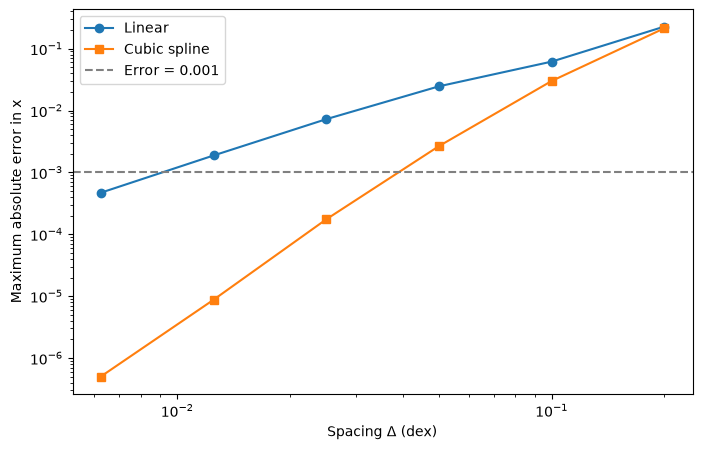

In [112]:
'Problem 1b'

from scipy.interpolate import CubicSpline

nH = 1e14
spacings = [0.2, 0.1, 0.05, 0.025, 0.0125, 0.00625]

def ionization(logT):
    T = 10**logT
    S = (2.415e15 / nH) * T**1.5 * np.exp(-157800 / T)
    return 2 / (1 + np.sqrt(1 + 4 / S))

def linear_interp(x_table, y_table, x_fine):
    indices = np.searchsorted(x_table, x_fine, side="right") - 1
    indices = np.clip(indices, 0, len(x_table) - 2)

    x0 = x_table[indices]
    x1 = x_table[indices + 1]
    y0 = y_table[indices]
    y1 = y_table[indices + 1]

    return y0 + (y1 - y0) * (x_fine - x0) / (x1 - x0)

#Fine grid for exact x solution
logT_fine = np.linspace(3.7, 4.3, 100001)
x_exact = ionization(logT_fine)

linear_errors = []
cubic_errors = []

for delta in spacings:
    n = round((4.3 - 3.7) / delta) + 1 #rounded to get an integer and added 1 for linspace
    logT_table = np.linspace(3.7, 4.3, n)
    x_table = ionization(logT_table)

    x_linear = linear_interp(logT_table, x_table, logT_fine)

    #Cubic spline with not-a-knot end conditions
    spline = CubicSpline(
        logT_table, x_table, bc_type="not-a-knot"
    )
    x_cubic = spline(logT_fine)

    linear_errors.append(np.max(np.abs(x_linear - x_exact)))
    cubic_errors.append(np.max(np.abs(x_cubic - x_exact)))

#Slopes from the smallest spacings
slope_linear = np.log10(linear_errors[-1] / linear_errors[-2]) / np.log10(spacings[-1] / spacings[-2])
slope_cubic = np.log10(cubic_errors[-1] / cubic_errors[-2]) / np.log10(spacings[-1] / spacings[-2])

print("Linear slope:", f"{slope_linear:.2f}")
print("Cubic slope:", f"{slope_cubic:.2f}")

plt.figure(figsize=(8, 5))
plt.loglog(spacings, linear_errors, 'o-', label="Linear")
plt.loglog(spacings, cubic_errors, 's-', label="Cubic spline")
plt.axhline(1e-3, color='gray', linestyle='--', label="Error = 0.001")

plt.xlabel(r"Spacing $\Delta$ (dex)")
plt.ylabel("Maximum absolute error in x")
plt.legend()
plt.show()

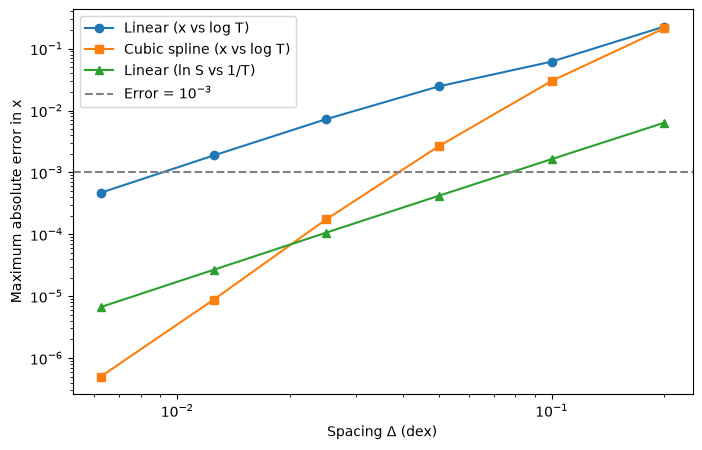

In [113]:
'Problem 1c'

nH = 1e14
spacings = [0.2, 0.1, 0.05, 0.025, 0.0125, 0.00625]

logT_fine = np.linspace(3.7, 4.3, 100001)
x_exact = ionization(logT_fine)

def lnS(T):
    return np.log(2.415e15 / nH) - 1.5 * np.log(1/T) - 157800 / T

lnS_errors = []

for delta in spacings:
    n = round((4.3 - 3.7) / delta) + 1
    logT_table = np.linspace(3.7, 4.3, n)
    T_table = 10**logT_table
    lnS_table = lnS(T_table)

    # Fine grid
    T_fine = 10**logT_fine
   
    # interpolation requires increasing x coordinates
    y_interp = linear_interp(1/T_table[::-1], lnS_table[::-1], 1/T_fine)

    S_interp = np.exp(y_interp)
    x_interp = 2 / (1 + np.sqrt(1 + 4 / S_interp))

    error = np.max(np.abs(x_interp - x_exact))
    lnS_errors.append(error)


plt.figure(figsize=(8, 5))
plt.loglog(spacings, linear_errors, 'o-', label="Linear (x vs log T)")
plt.loglog(spacings, cubic_errors, 's-', label="Cubic spline (x vs log T)")
plt.loglog(spacings, lnS_errors, '^-',
           label="Linear (ln S vs 1/T)")

plt.axhline(1e-3, color='gray', linestyle='--',
            label=r"Error = $10^{-3}$")

plt.xlabel(r"Spacing $\Delta$ (dex)")
plt.ylabel("Maximum absolute error in x")
plt.legend()
plt.show()

Wind speed at Earth: 430.28 km/s


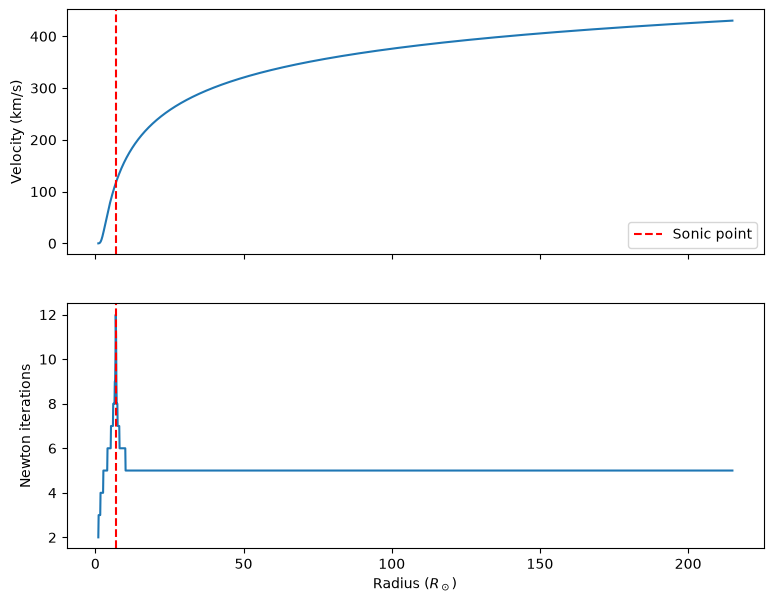

In [114]:
'Problem 2c'

#all in cgs units
GMsun = 1.327e26
Rsun = 6.96e10
au = 1.496e13 
kB = 1.380649e-16
mH = 1.6735575e-24
temp = 1e6 
mu = 0.6

cs = np.sqrt(kB * temp / (mu * mH))
rs = GMsun / (2 * cs**2)

tol = 1e-14
nmax = 200

def parker_velocity(r):

    if r == rs:
        return cs, 0

    c = 4 * np.log(r / rs) + 4 * rs / r - 3

    if r < rs:
        w = np.exp(-c)
    else:
        w = 2 * c

    for n in range(1, nmax + 1):
        f = w - np.log(w) - c
        fp = 1 - 1 / w

        correction = f / fp
        w_new = w - correction

        if abs(correction / w_new) < tol:
            return cs * np.sqrt(w_new), n

        w = w_new

print(f"Wind speed at Earth: {parker_velocity(au)[0] / 1e5:.2f} km/s")

radii = np.linspace(Rsun, au, 2000)

velocities = []
iterations = []

for r in radii:
    v, n = parker_velocity(r)
    velocities.append(v / 1e5)
    iterations.append(n)

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

axes[0].plot(radii / Rsun, velocities)
axes[0].axvline(rs / Rsun, color="red", linestyle="--", label="Sonic point")
axes[0].set_ylabel("Velocity (km/s)")
axes[0].legend()

axes[1].plot(radii / Rsun, iterations)
axes[1].axvline(rs / Rsun, color="red", linestyle="--")
axes[1].set_xlabel(r"Radius ($R_\odot$)")
axes[1].set_ylabel("Newton iterations")

plt.show()


Sonic point to Earth
Reference travel time (from Gauss-Legendre with 128 points): 4.85806 days
Trapezoid, N=128: 4.86021 days
Simpson, N=128: 4.85815 days
Gauss-Legendre, N=128: 4.85806 days

2 solar radii to sonic point
Reference travel time (from Gauss-Legendre with 128 points): 1.07222 days
Trapezoid, N=128: 1.07262 days
Simpson, N=128: 1.07222 days
Gauss-Legendre, N=128: 1.07222 days


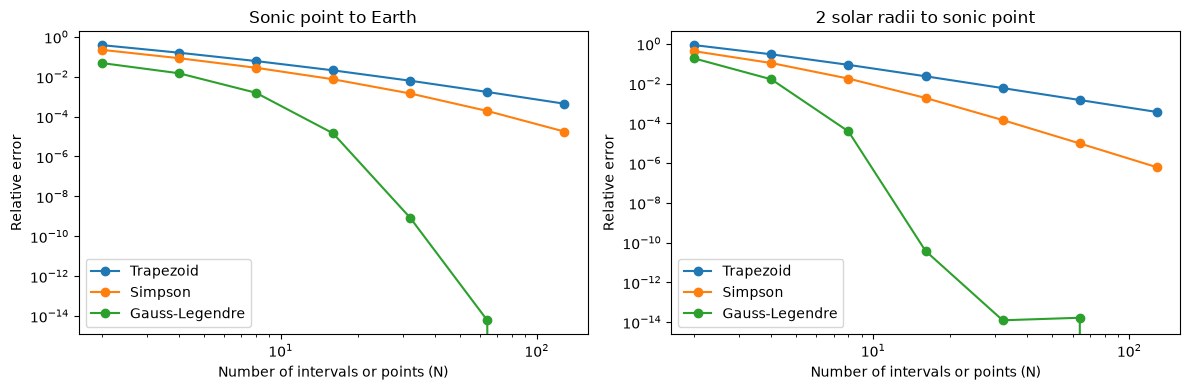

Travel time from solar surface to Earth:


Trapezoid
N = 128: 286.344695 days

Simpson
N = 128: 193.036416 days

Gauss-Legendre
N = 128: 41.377418 days


In [119]:
'Problem 2c cont.'

from numpy.polynomial.legendre import leggauss

def integrand(r):
    v, _ = parker_velocity(r)
    return 1 / v

def trapezoid(a, b, N):
    x = np.linspace(a, b, N + 1)
    y = np.array([integrand(r) for r in x])
    h = (b - a) / N

    return h * (0.5*y[0] + np.sum(y[1:-1]) + 0.5*y[-1])

def simpson(a, b, N):
    x = np.linspace(a, b, N + 1)
    y = np.array([integrand(r) for r in x])
    h = (b - a) / N

    return h / 3 * (
        y[0] + y[-1]
        + 4 * np.sum(y[1:-1:2])
        + 2 * np.sum(y[2:-1:2])
    )

def gauss_legendre(a, b, N):
    nodes, weights = leggauss(N)

    #Transform nodes from [-1, 1] to [a, b]
    x = (b-a)/2 * nodes + (a+b)/2
    y = np.array([integrand(r) for r in x])

    return (b-a)/2 * np.sum(weights * y)


Ns = 2 ** np.arange(1, 8)  #2, 4, 8, 16, 32, 64, 128

intervals = [
    (rs, au, "Sonic point to Earth"),
    (2*Rsun, rs, "2 solar radii to sonic point")
]

methods = {
    "Trapezoid": trapezoid,
    "Simpson": simpson,
    "Gauss-Legendre": gauss_legendre
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (a, b, title) in zip(axes, intervals):

    reference = gauss_legendre(a, b, 128)
    print(f"\n{title}")
    print(f"Reference travel time (from Gauss-Legendre with 128 points): {reference/86400:.5f} days")

    for name, method in methods.items():
        times = np.array([method(a, b, N) for N in Ns])
        errors = np.abs(times - reference) / reference

        ax.loglog(Ns, errors, "o-", label=name)

        print(f"{name}, N=128: {times[-1]/86400:.5f} days")

    ax.set_xlabel("Number of intervals or points (N)")
    ax.set_ylabel("Relative error")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

a, b = Rsun, au

print("Travel time from solar surface to Earth:\n")

for name, method in methods.items():
    print(f"\n{name}")
    t = method(a, b, 128) / 86400
    print(f"N = {128:3d}: {t:.6f} days")

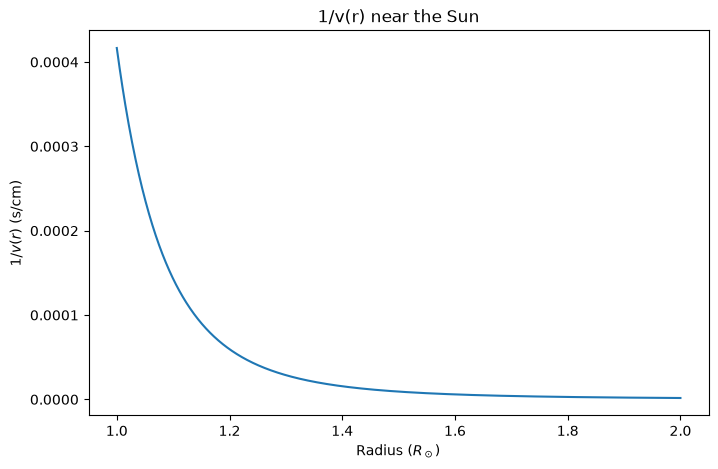

In [116]:
'Problem 2c cont.'

r_inner = np.linspace(Rsun, 2*Rsun, 1000)

inverse_v = np.array([integrand(r) for r in r_inner])

plt.figure(figsize=(8, 5))
plt.plot(r_inner / Rsun, inverse_v)

plt.xlabel(r"Radius ($R_\odot$)")
plt.ylabel(r"$1/v(r)$ (s/cm)")
plt.title("1/v(r) near the Sun")
plt.show()

In [ ]:
'Problem 2d'

#Transformed integrand in u
def integrand_u(u):
    r = 1 / u
    v, _ = parker_velocity(r)
    return 1 / (u**2 * v)

def trapezoid_u(a, b, N):
    u = np.linspace(a, b, N + 1)
    y = np.array([integrand_u(x) for x in u])
    h = (b - a) / N

    return h * (0.5*y[0] + np.sum(y[1:-1]) + 0.5*y[-1])

def simpson_u(a, b, N):
    u = np.linspace(a, b, N + 1)
    y = np.array([integrand_u(x) for x in u])
    h = (b - a) / N

    return (h / 3) * (
        y[0] + y[-1]
        + 4*np.sum(y[1:-1:2])
        + 2*np.sum(y[2:-1:2])
    )

def gauss_legendre_u(a, b, N):
    nodes, weights = leggauss(N)

    u = (b-a)/2 * nodes + (a+b)/2
    y = np.array([integrand_u(x) for x in u])

    return (b-a)/2 * np.sum(weights * y)


Ns = 2 ** np.arange(1, 7)  #2, 4, 8, 16, 32, 64

a = 1 / rs
b = 1 / Rsun

#Travel time from sonic point to Earth
t_outer = gauss_legendre(rs, au, 128)

methods_u = {
    "Trapezoid": trapezoid_u,
    "Simpson": simpson_u,
    "Gauss-Legendre": gauss_legendre_u
}

results = {}

for name, method in methods_u.items():
    times = []

    for N in Ns:
        t_inner = method(a, b, N)
        t_total = (t_inner + t_outer) / 86400
        times.append(t_total)

    results[name] = np.array(times)

print("Travel time from sonic point to Earth (days):", f"{t_outer/86400:.6f}")

for i, N in enumerate(Ns):
    print(
        f"{N:5d} "
        f"{results['Trapezoid'][i]:15.6f} "
        f"{results['Simpson'][i]:15.6f} "
        f"{results['Gauss-Legendre'][i]:15.6f}"
    )

Travel time from sonic point to Earth (days): 4.858062
    2       80.913513       57.928590       31.907186
    4       53.149922       43.895391       41.255720
    8       44.491822       41.605789       41.377458
   16       42.168120       41.393552       41.377468
   32       41.575911       41.378508       41.377468
   64       41.427128       41.377533       41.377468
